# Noise prediction and reverse diffusion

Can a model learn the noise component used to corrupt a digit image?

I implement a finite DDPM schedule, train a noise predictor and run its reverse process. The project connects HSE's probabilistic-model laboratory to an image-generation example small enough to inspect on CPU.

## Run settings

The default run uses CPU and a small training budget. Set `PROJECT_FULL=1` before opening the notebook for the longer run. Both modes use the same data split and evaluation code. A short run checks the experiment; the number of epochs limits what its scores can establish.

In [3]:
import inspect
import json
import os
from pathlib import Path
import sys

import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset

root = Path.cwd()
while not (root / "pyproject.toml").exists() and root != root.parent:
    root = root.parent
if not (root / "pyproject.toml").exists():
    raise FileNotFoundError("Open this notebook inside the repository")
sys.path.insert(0, str(root / "src"))
from deep_projects.training import (
    digits_data,
    image_grid,
    plot_history,
    seed_everything,
)

QUICK = os.environ.get("PROJECT_FULL", "0") != "1"
EPOCHS = 6 if QUICK else 40
seed_everything(1031)
output = root / "figures" / "11_denoising_diffusion"
output.mkdir(parents=True, exist_ok=True)
(root / "results").mkdir(exist_ok=True)
print({"torch": torch.__version__, "device": "cpu", "epochs": EPOCHS, "seed": 1031})

{'torch': '2.14.1+cu130', 'device': 'cpu', 'epochs': 40, 'seed': 1031}


## Forward process

The forward sample is $x_t=\sqrt{\bar\alpha_t}x_0+\sqrt{1-\bar\alpha_t}\epsilon$. Here $\alpha_t=1-\beta_t$ and $\bar\alpha_t$ is the cumulative product. Fifty steps use a deliberately strong noise schedule so the final marginal is close to the standard-normal sampling distribution.

    def corrupt(self, images, timesteps):
        noise = torch.randn_like(images)
        cumulative_alpha = self.alpha_bar[timesteps].view(-1, 1, 1, 1)
        return cumulative_alpha.sqrt() * images + (1 - cumulative_alpha).sqrt() * noise, noise



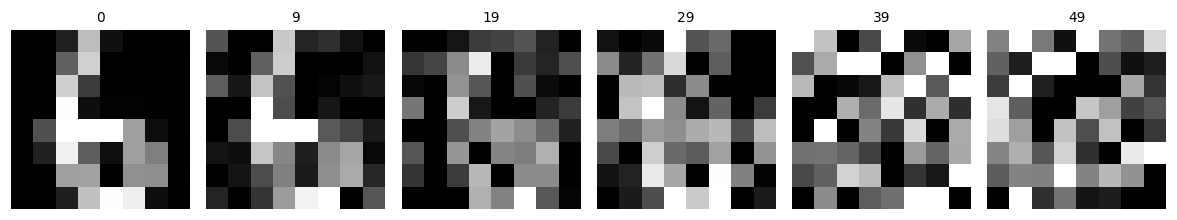

Final cumulative alpha: 0.04364103823900223


In [5]:
from deep_projects.models import Diffusion, NoisePredictor

data = digits_data(8)
images = data.train.tensors[0] * 2 - 1
diffusion = Diffusion(50)
print(inspect.getsource(Diffusion.corrupt))
assert torch.all(diffusion.alpha_bar[1:] < diffusion.alpha_bar[:-1])
steps = torch.tensor([0, 9, 19, 29, 39, 49])
noisy, noise = diffusion.corrupt(images[:1].repeat(6, 1, 1, 1), steps)
image_grid(((noisy + 1) / 2).clamp(0, 1), output / "forward_noise.png", steps.tolist())
print("Final cumulative alpha:", float(diffusion.alpha_bar[-1]))

## Noise-prediction training

Each minibatch draws independent timesteps and Gaussian noise. The validation corruption is sampled once and then fixed for checkpoint selection. MSE against the actual noise measures prediction directly, without requiring a reverse sample to be visually convincing.

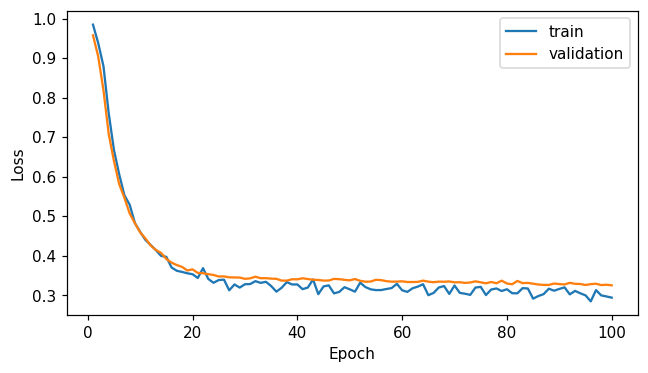

In [7]:
import copy

model = NoisePredictor(50)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
loader = DataLoader(TensorDataset(images), 64, shuffle=True)
validation_images = data.validation.tensors[0] * 2 - 1
validation_steps = torch.randint(0, 50, (len(validation_images),))
validation_noisy, validation_noise = diffusion.corrupt(
    validation_images, validation_steps
)
history, best_loss, best_weights = [], float("inf"), None
for epoch in range(12 if QUICK else 100):
    model.train()
    total, count = 0.0, 0
    for (clean,) in loader:
        timesteps = torch.randint(0, 50, (len(clean),))
        noisy, noise = diffusion.corrupt(clean, timesteps)
        optimizer.zero_grad(set_to_none=True)
        loss = F.mse_loss(model(noisy, timesteps), noise)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 5)
        optimizer.step()
        total += float(loss.detach()) * len(clean)
        count += len(clean)
    model.eval()
    with torch.inference_mode():
        validation_loss = float(
            F.mse_loss(model(validation_noisy, validation_steps), validation_noise)
        )
    history.append(
        {
            "epoch": epoch + 1,
            "train_loss": total / count,
            "validation_loss": validation_loss,
        }
    )
    if validation_loss < best_loss:
        best_loss, best_weights = validation_loss, copy.deepcopy(model.state_dict())
model.load_state_dict(best_weights)
plot_history(pd.DataFrame(history), output / "loss.png")

## Reverse sampling

The reverse process estimates the clean image from predicted noise, clips that estimate to the training intensity range of minus one through one and computes the Gaussian posterior mean from it. Clipping constrains the estimated clean image; the noisy intermediate states remain unconstrained. Noise variance uses $\tilde\beta_t=\beta_t(1-\bar\alpha_{t-1})/(1-\bar\alpha_t)$ and becomes zero at the final step. The generated images are clipped only for display. Raw sample magnitudes are retained as a diagnostic.

    @torch.inference_mode()
    def sample(self, model, count=8):
        model.eval()
        images = torch.randn(count, 1, 8, 8)
        for step in range(len(self.beta) - 1, -1, -1):
            timesteps = torch.full((count,), step, dtype=torch.long)
            predicted_noise = model(images, timesteps)
            alpha_bar = self.alpha_bar[step]
            clean_estimate = (images - (1 - alpha_bar).sqrt() * predicted_noise) / alpha_bar.sqrt()
            # The training images lie in [-1, 1]; clipping constrains the estimated clean image.
            clean_estimate = clean_estimate.clamp(-1, 1)
            previous_alpha_bar = self.alpha_bar[step - 1] if step > 0 else torch.tensor(1.0)
            clean_coefficient = self.beta[step] * previous_alpha_bar.sqrt() / (1 - alpha_bar)
            noisy_coefficient = self.alpha[step].sqrt() * (1 - previous_alpha_bar) / (1 - alpha_bar)
            mean = clean_coefficient * clean_estimate + noisy_coefficient * images
            if step

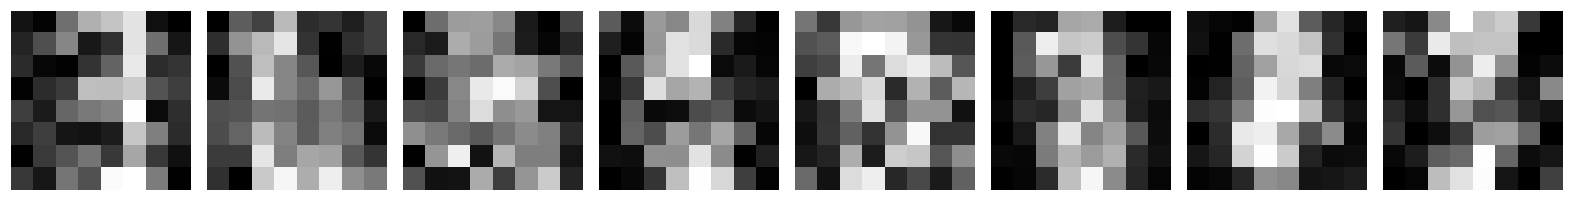

{'noise_prediction_test_mse': 0.3263086676597595, 'zero_predictor_mse': 1.0023185014724731, 'steps': 50, 'final_alpha_bar': 0.04364103823900223, 'sample_max_abs': 0.9998340606689453, 'quality_metric_measured': False}


In [9]:
print(inspect.getsource(Diffusion.sample))
model.eval()
generated = diffusion.sample(model, 8)
assert torch.isfinite(generated).all()
image_grid(((generated + 1) / 2).clamp(0, 1), output / "samples.png")
test_images = data.test.tensors[0] * 2 - 1
test_steps = torch.randint(0, 50, (len(test_images),))
test_noisy, test_noise = diffusion.corrupt(test_images, test_steps)
with torch.inference_mode():
    test_mse = float(F.mse_loss(model(test_noisy, test_steps), test_noise))
results = {
    "noise_prediction_test_mse": test_mse,
    "zero_predictor_mse": float(test_noise.square().mean()),
    "steps": 50,
    "final_alpha_bar": float(diffusion.alpha_bar[-1]),
    "sample_max_abs": float(generated.abs().max()),
    "quality_metric_measured": False,
}
print(results)

## Reading the result

Noise prediction is the measured task; visual sample quality is inspected separately. The small MLP and short training schedule may leave recognizable structure weak. A finite reverse process verifies the implementation but does not establish a strong image generator.

Recorded run: After 100 epochs, test noise-prediction MSE was 0.3263, compared with 1.0023 for predicting zero noise. The estimated clean-image clipping kept final samples within the training intensity range. The grid is still low resolution and is inspected as an implementation result.

In [11]:
result_path = root / "results" / "11_denoising_diffusion.json"
result_path.write_text(json.dumps(results, indent=2, allow_nan=False) + "\n")
print(result_path.relative_to(root))

results/11_denoising_diffusion.json


## Next experiment

Use sinusoidal time embeddings and a convolutional noise predictor. Compare sampling schedules at equal compute, then add held-out distribution metrics suited to the image resolution.

## Sources

[HSE deep learning course](https://github.com/mryab/dl-hse-ami) and its [wiki syllabus](https://wiki.cs.hse.ru/Глубинное_обучение_2022). week10_probmodels. [DDPM](https://arxiv.org/abs/2006.11239).

The implementations here were written for this project. Course notebooks and their saved weights are reference material; they are not redistributed.